# Research Assignment: Recursive Spectral Modularity Partitioning of the Karate Club Network
**Aditya Gupta (IMS25006)**

**Goal.** Repeatedly bisect Zachary's Karate Club network using the leading eigenvector of the modularity matrix (Newman, 2006), and study how four node-level network metrics change as the network is broken into communities.

**Contents:** 1) Load graph · 2) Original graph · 3) Adjacency and modularity matrices · 4) Recursive spectral partitioning · 5) Partition visualisation · 6) Validation against the real club split · 7) Metrics after each split · 8) Metric evolution · 9) Frequently top-ranked nodes · 10) Final modularity and comparison · 11) Conclusions

## 1. Import libraries and load the graph
The Karate Club graph has 34 nodes (members) and 78 edges (recorded friendships). Each node also carries a `club` attribute recording which faction the member joined after the club split (`Mr. Hi` or `Officer`), which gives us a ground truth to validate against later.

> **Note on edge weights.** Recent versions of NetworkX attach an interaction-strength `weight` to every edge of this graph. Newman's modularity matrix assumes an *unweighted* graph with `m = 78` edges, so every matrix and metric below is built **ignoring the weights** (`weight=None`). Mixing weighted entries in `A` with `m = 78` silently produces a wrong modularity matrix.

In [1]:
import numpy as np
import pandas as pd
import networkx as nx
import matplotlib.pyplot as plt
from sklearn.metrics import normalized_mutual_info_score, adjusted_rand_score

plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False})

G = nx.karate_club_graph()
nodes = list(G.nodes())
n, m = G.number_of_nodes(), G.number_of_edges()

# Ground truth: 0 = Mr. Hi's faction, 1 = Officer's faction
club = np.array([0 if G.nodes[v]["club"] == "Mr. Hi" else 1 for v in nodes])

print("Number of nodes:", n)
print("Number of edges:", m)
print("Edges carry weights in this NetworkX version:", nx.is_weighted(G), "(ignored below)")
print("Faction sizes (Mr. Hi / Officer):", (club == 0).sum(), "/", (club == 1).sum())

Number of nodes: 34
Number of edges: 78
Edges carry weights in this NetworkX version: True (ignored below)
Faction sizes (Mr. Hi / Officer): 17 / 17


## 2. Visualise the original graph
A fixed spring layout (`seed=42`) is reused in every figure, so nodes stay in the same place and plots can be compared directly. Colours show the real post-split factions.

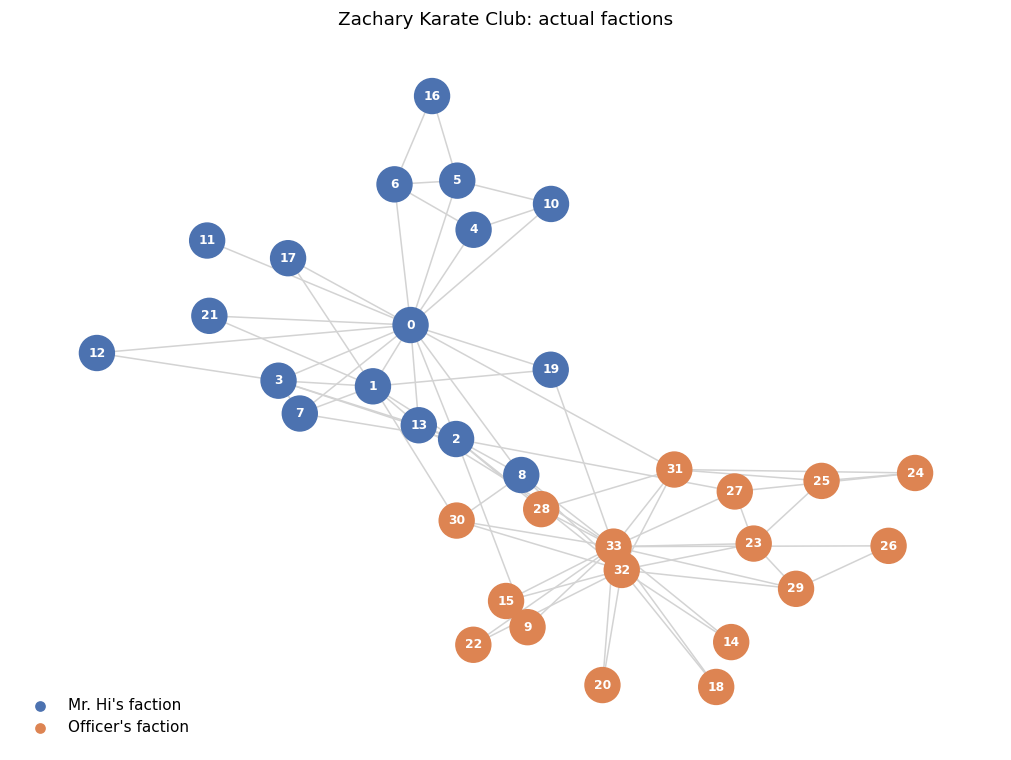

In [2]:
pos = nx.spring_layout(G, seed=42)
faction_colours = ["#4C72B0" if c == 0 else "#DD8452" for c in club]

plt.figure(figsize=(9, 6.5))
nx.draw(G, pos, with_labels=True, node_size=520, node_color=faction_colours,
        edge_color="lightgray", font_size=8, font_color="white", font_weight="bold")
plt.scatter([], [], c="#4C72B0", label="Mr. Hi's faction")
plt.scatter([], [], c="#DD8452", label="Officer's faction")
plt.legend(loc="lower left", frameon=False)
plt.title("Zachary Karate Club: actual factions")
plt.axis("off")
plt.show()

## 3. Adjacency matrix and modularity matrix
With adjacency matrix $A$, degrees $k_i$ and $m$ edges, the modularity matrix is

$$B_{ij} = A_{ij} - \frac{k_i k_j}{2m}.$$

Sanity checks: $A$ must count exactly $m$ edges, $B$ must be symmetric, and every row of $B$ must sum to zero (so $\mathbf{1}$ is an eigenvector with eigenvalue 0, which is why a trivial "everyone in one group" split is never positive).

In [3]:
A = nx.to_numpy_array(G, nodelist=nodes, weight=None)   # unweighted 0/1 matrix
k = A.sum(axis=1)
B = A - np.outer(k, k) / (2 * m)

print("Adjacency matrix shape:", A.shape, "| edges counted in A:", int(A.sum() / 2), "(expected", m, ")")
print("Modularity matrix shape:", B.shape)
print("A symmetric?        ", np.allclose(A, A.T))
print("B symmetric?        ", np.allclose(B, B.T))
print("Rows of B sum to 0? ", np.allclose(B.sum(axis=1), 0))

assert A.sum() / 2 == m and np.allclose(B, B.T) and np.allclose(B.sum(axis=1), 0)

Adjacency matrix shape: (34, 34) | edges counted in A: 78 (expected 78 )
Modularity matrix shape: (34, 34)
A symmetric?         True
B symmetric?         True
Rows of B sum to 0?  True


## 4. Recursive spectral modularity partitioning
For a community $g$ with indicator vector $s \in \{+1,-1\}^{|g|}$, the change in modularity from splitting $g$ in two is (Newman 2006, eq. 6)

$$\Delta Q = \frac{1}{4m}\, s^{T} B^{(g)} s, \qquad B^{(g)}_{ij} = B_{ij} - \delta_{ij}\sum_{l\in g} B_{il}.$$

The correction term $\delta_{ij}\sum_{l\in g}B_{il}$ matters: simply taking the sub-block of $B$ ignores the edges and degree mass that connect $g$ to the rest of the network, and the splitting criterion becomes incorrect. For the first split $g$ is the whole graph, the row sums vanish and $B^{(g)} = B$; deeper in the recursion they do not.

**Algorithm.** For each current community:
1. Build $B^{(g)}$ from the original $B$.
2. Find its largest eigenvalue $\beta_1$ and eigenvector $u_1$.
3. Stop if $\beta_1 \le$ tolerance (the community is indivisible).
4. Split by the sign of $u_1$ and compute $\Delta Q$; stop if $\Delta Q \le$ tolerance.
5. Otherwise replace the community by its two halves and queue both for further splitting.

A small tolerance (`1e-8`) prevents floating-point round-off near zero from being treated as a positive eigenvalue. Splits are processed in a queue (first in, first out), and the full partition plus its modularity $Q$ is stored after every split.

In [4]:
TOL = 1e-8

def modularity(partition):
    """Q = (1/2m) * sum over communities of the sum of B_ij inside each community."""
    q = sum(B[np.ix_(c, c)].sum() for c in partition) / (2 * m)
    return round(q, 12) + 0.0                           # avoids printing "-0.000" for Q = 0

def bisect(community):
    """Try to split one community. Returns (group1, group2, beta1, dQ) or None if indivisible."""
    if len(community) < 2:
        return None
    B_sub = B[np.ix_(community, community)]
    B_g = B_sub - np.diag(B_sub.sum(axis=1))          # generalised modularity matrix

    eigenvalues, eigenvectors = np.linalg.eigh(B_g)   # symmetric -> eigh (ascending order)
    beta1, u1 = eigenvalues[-1], eigenvectors[:, -1]
    if beta1 <= TOL:
        return None

    s = np.where(u1 > 0, 1.0, -1.0)
    dQ = s @ B_g @ s / (4 * m)
    if dQ <= TOL:
        return None

    group1 = [v for v, si in zip(community, s) if si > 0]
    group2 = [v for v, si in zip(community, s) if si < 0]
    return group1, group2, float(beta1), float(dQ)

def spectral_partition():
    communities = [nodes.copy()]
    history = [{"partition": [nodes.copy()], "Q": modularity(communities)}]   # iteration 0
    log, queue = [], [nodes.copy()]

    while queue:
        current = queue.pop(0)
        result = bisect(current)
        if result is None:
            continue
        group1, group2, beta1, dQ = result

        q_before = modularity(communities)
        communities.remove(current)
        communities.extend([group1, group2])
        q_after = modularity(communities)
        assert np.isclose(q_after - q_before, dQ), "dQ formula and direct modularity disagree"

        history.append({"partition": [c.copy() for c in communities], "Q": q_after})
        log.append({"split": len(log) + 1, "parent size": len(current),
                    "children": f"{len(group1)} + {len(group2)}",
                    "largest eigenvalue": beta1, "delta Q": dQ, "Q after": q_after})
        queue.extend([group1, group2])

    return communities, history, pd.DataFrame(log).set_index("split")

communities, split_history, split_log = spectral_partition()
partitions = [h["partition"] for h in split_history]          # index 0 = original graph

print("Number of splits:", len(split_log))
print("Number of final communities:", len(communities))
print()
print(split_log.round(4).to_string())
print("\nFinal communities:")
for i, community in enumerate(sorted(communities, key=lambda c: min(c)), start=1):
    print(f"  Community {i} ({len(community):>2} nodes): {sorted(community)}")

Number of splits: 3
Number of final communities: 4

       parent size children  largest eigenvalue  delta Q  Q after
split                                                            
1               34  16 + 18              4.9771   0.3715   0.3715
2               16    7 + 9              1.1785   0.0012   0.3727
3               18   12 + 6              0.8594   0.0207   0.3934

Final communities:
  Community 1 ( 7 nodes): [0, 4, 5, 6, 10, 11, 16]
  Community 2 ( 9 nodes): [1, 2, 3, 7, 12, 13, 17, 19, 21]
  Community 3 (12 nodes): [8, 9, 14, 15, 18, 20, 22, 26, 29, 30, 32, 33]
  Community 4 ( 6 nodes): [23, 24, 25, 27, 28, 31]


/var/folders/gp/7cdvnjqj4fzdqd9svs0k78xh0000gn/T/ipykernel_75327/154274596.py:21: RuntimeWarning: divide by zero encountered in matmul
  dQ = s @ B_g @ s / (4 * m)
/var/folders/gp/7cdvnjqj4fzdqd9svs0k78xh0000gn/T/ipykernel_75327/154274596.py:21: RuntimeWarning: overflow encountered in matmul
  dQ = s @ B_g @ s / (4 * m)
/var/folders/gp/7cdvnjqj4fzdqd9svs0k78xh0000gn/T/ipykernel_75327/154274596.py:21: RuntimeWarning: invalid value encountered in matmul
  dQ = s @ B_g @ s / (4 * m)


## 5. Visualise the graph after every split
Same layout as before; each current community gets its own colour and nodes keep their original IDs. The title of each panel gives the modularity $Q$ of that partition.

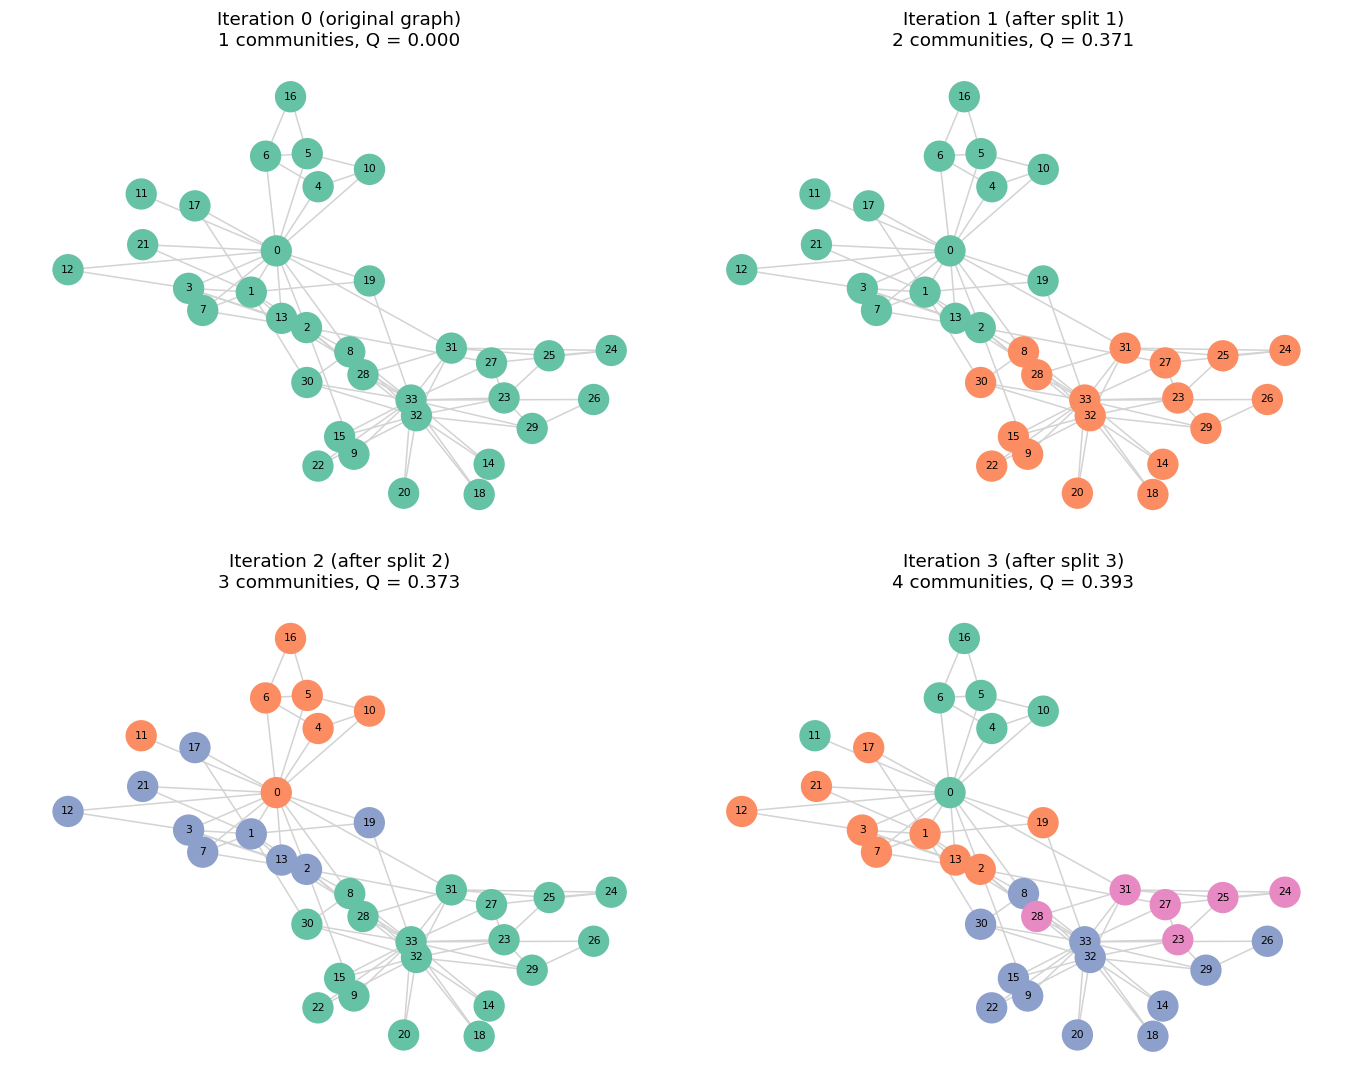

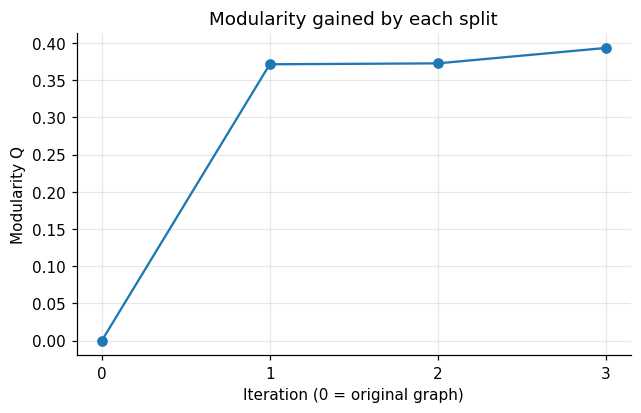

In [5]:
def community_colours(partition):
    lookup = {v: i for i, c in enumerate(partition) for v in c}
    return [lookup[v] for v in nodes]

n_panels = len(partitions)
cols = 2
rows = int(np.ceil(n_panels / cols))
fig, axes = plt.subplots(rows, cols, figsize=(6.2 * cols, 5 * rows))
axes = np.atleast_1d(axes).ravel()

for ax, (it, partition) in zip(axes, enumerate(partitions)):
    nx.draw(G, pos, ax=ax, with_labels=True, node_size=380, font_size=7,
            node_color=community_colours(partition), cmap=plt.cm.Set2, vmin=0, vmax=7,
            edge_color="lightgray")
    label = "original graph" if it == 0 else f"after split {it}"
    ax.set_title(f"Iteration {it} ({label})\n{len(partition)} communities, Q = {split_history[it]['Q']:.3f}")
for ax in axes[n_panels:]:
    ax.axis("off")
plt.tight_layout()
plt.show()

# Modularity as a function of the number of splits
plt.figure(figsize=(6.5, 3.8))
plt.plot(range(n_panels), [h["Q"] for h in split_history], marker="o")
plt.xticks(range(n_panels))
plt.xlabel("Iteration (0 = original graph)")
plt.ylabel("Modularity Q")
plt.title("Modularity gained by each split")
plt.grid(alpha=0.3)
plt.show()

## 6. Validate against the real club split
Zachary recorded which faction each member joined when the club divided. A good community-detection result should recover this split. We compare each partition to the ground truth using normalised mutual information (NMI) and the adjusted Rand index (ARI); both equal 1 for a perfect match.

In [6]:
def labels(partition):
    lab = np.zeros(n, dtype=int)
    for i, c in enumerate(partition):
        lab[list(c)] = i
    return lab

validation = pd.DataFrame({
    "communities": [len(p) for p in partitions],
    "Q": [h["Q"] for h in split_history],
    "NMI vs club": [normalized_mutual_info_score(club, labels(p)) for p in partitions],
    "ARI vs club": [adjusted_rand_score(club, labels(p)) for p in partitions],
}).rename_axis("iteration")
print(validation.round(3).to_string())

# Which members does the very first split put on the 'wrong' side?
first = labels(partitions[1])
flip = first if (first == club).sum() > (first != club).sum() else 1 - first   # fix arbitrary side labelling
misplaced = [v for v in nodes if flip[v] != club[v]]
print("\nFirst split vs real factions: misplaced members =", misplaced,
      f"({n - len(misplaced)}/{n} correct)")

           communities      Q  NMI vs club  ARI vs club
iteration                                              
0                    1  0.000        0.000        0.000
1                    2  0.371        0.837        0.882
2                    3  0.373        0.679        0.655
3                    4  0.393        0.579        0.435

First split vs real factions: misplaced members = [8] (33/34 correct)


## 7. Calculate network metrics after each split
For each snapshot, every metric is calculated on the **induced subgraph of the community** each node currently belongs to, so the values show how a node's position changes as its community is subdivided. The four metrics are degree centrality, betweenness centrality, closeness centrality and the clustering coefficient. The unsplit graph is stored as iteration 0.

Two things to keep in mind when reading the results:
- Centralities are *normalised by community size* (by $n_c-1$, or the corresponding pair count), so a node's raw degree can fall while its degree centrality rises, simply because its community got smaller.
- Closeness and betweenness assume a connected graph; the check below confirms every community is connected at every iteration.

In [7]:
metric_names = ["Degree centrality", "Betweenness centrality",
                "Closeness centrality", "Clustering coefficient"]

def calculate_metrics(partition):
    """Return {metric: {node: value}} using each node's community-induced subgraph."""
    snapshot = {metric: {} for metric in metric_names}
    for community in partition:
        H = G.subgraph(community)
        assert nx.is_connected(H), f"community {sorted(community)} is disconnected"
        snapshot["Degree centrality"].update(nx.degree_centrality(H))
        snapshot["Betweenness centrality"].update(nx.betweenness_centrality(H))
        snapshot["Closeness centrality"].update(nx.closeness_centrality(H))
        snapshot["Clustering coefficient"].update(nx.clustering(H))
    return snapshot

snapshots = [calculate_metrics(p) for p in partitions]

# metric_tables[metric] is a (nodes x iterations) DataFrame
metric_tables = {
    metric: pd.DataFrame({it: pd.Series(s[metric]) for it, s in enumerate(snapshots)}).loc[nodes]
    for metric in metric_names
}
print("Snapshots stored:", len(snapshots), "| nodes measured in each:", n)
print("All communities connected at every iteration: True")
print("Any missing values:", any(t.isna().any().any() for t in metric_tables.values()))

Snapshots stored: 4 | nodes measured in each: 34
All communities connected at every iteration: True
Any missing values: False


## 8. Plot the evolution of each metric
Each thin grey line is one node; the x-axis is the iteration (0 = original graph). Four nodes per panel are highlighted and labelled so the plot stays readable: those with the highest average value, except for the clustering coefficient (where many nodes are tied at 1.0), where the four nodes that change the most are shown.

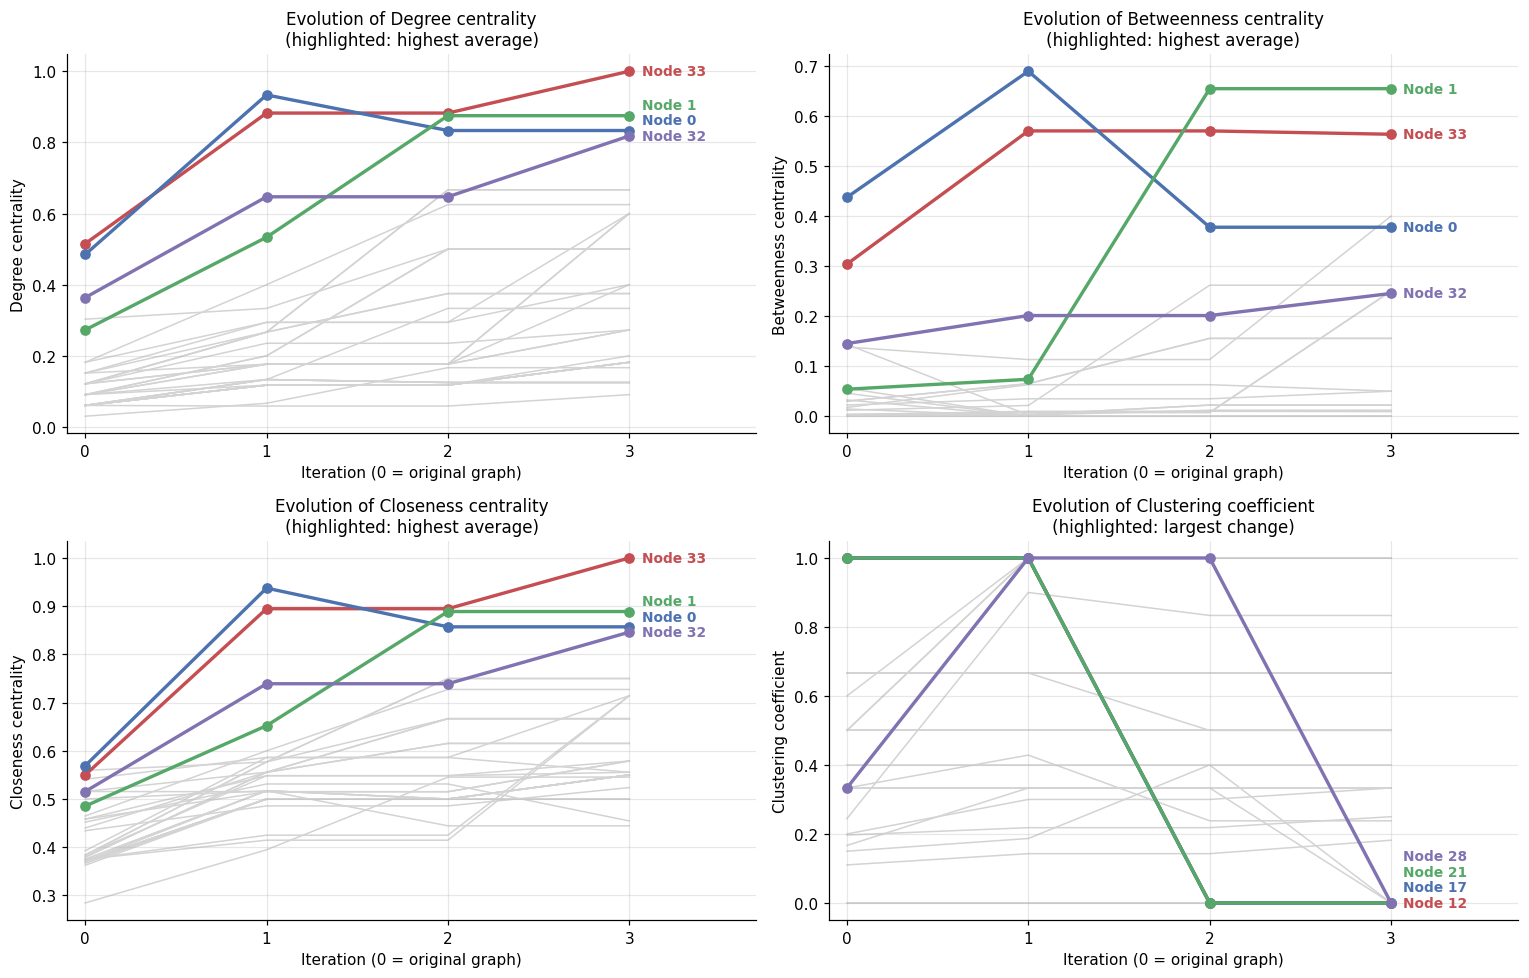

In [8]:
iterations = list(range(len(snapshots)))
fig, axes = plt.subplots(2, 2, figsize=(14, 9))
palette = ["#C44E52", "#4C72B0", "#55A868", "#8172B2"]

for ax, metric in zip(axes.ravel(), metric_names):
    table = metric_tables[metric]
    for v in nodes:
        ax.plot(iterations, table.loc[v], color="lightgray", linewidth=1, zorder=1)

    # Clustering is 1.0 for many nodes, so highlight the nodes that change the most instead.
    if metric == "Clustering coefficient":
        top = table.std(axis=1).nlargest(4).index
        note = "highlighted: largest change"
    else:
        top = table.mean(axis=1).nlargest(4).index
        note = "highlighted: highest average"

    y_range = table.max().max() - table.min().min()
    label_y, last_y = {}, -np.inf
    for v in sorted(top, key=lambda v: table.loc[v].iloc[-1]):          # nudge labels apart
        y = max(table.loc[v].iloc[-1], last_y + 0.045 * y_range)
        label_y[v], last_y = y, y

    for colour, v in zip(palette, top):
        ax.plot(iterations, table.loc[v], marker="o", linewidth=2.2, color=colour, zorder=3)
        ax.annotate(f"Node {v}", (iterations[-1], label_y[v]), xytext=(8, 0),
                    textcoords="offset points", color=colour, fontsize=9,
                    va="center", fontweight="bold")

    ax.set_title(f"Evolution of {metric}\n({note})", fontsize=11)
    ax.set_xlabel("Iteration (0 = original graph)")
    ax.set_ylabel(metric)
    ax.set_xticks(iterations)
    ax.set_xlim(-0.1, iterations[-1] + 0.7)
    ax.grid(alpha=0.3)

plt.tight_layout()
plt.show()

## 9. Identify nodes that frequently rank highly
For each metric we count how often each node is in the top five across the stored iterations. Ties at the fifth place are all counted (clustering coefficient in particular has many nodes tied at 1.0, and a plain sort would pick between them arbitrarily by node number).

In [9]:
top_k = 5

def top_k_with_ties(series, k=top_k):
    threshold = series.nlargest(k).min()
    return series.index[series >= threshold - 1e-12]

counts = pd.DataFrame(0, index=nodes, columns=metric_names)
for metric in metric_names:
    for it in iterations:
        counts.loc[top_k_with_ties(metric_tables[metric][it]), metric] += 1

counts["Total"] = counts.sum(axis=1)
counts.index.name = "node"
print(f"Number of snapshots (out of {len(iterations)}) in which a node is in the top {top_k}, ties included\n")
print(counts.sort_values("Total", ascending=False).head(10).to_string())

print("\nTop 5 per metric (by count):")
for metric in metric_names:
    best = counts[metric].sort_values(ascending=False).head(5)
    print(f"  {metric:<24}", ", ".join(f"{v} ({c})" for v, c in best.items()))

Number of snapshots (out of 4) in which a node is in the top 5, ties included

      Degree centrality  Betweenness centrality  Closeness centrality  Clustering coefficient  Total
node                                                                                                
0                     4                       4                     4                       0     12
33                    4                       4                     4                       0     12
1                     4                       3                     3                       0     10
32                    3                       3                     3                       0      9
18                    0                       0                     0                       4      4
26                    0                       0                     0                       4      4
16                    0                       0                     0                       4      4
15          

## 10. Modularity of the final partition and comparison with other methods
The final modularity is computed directly from the matrix definition and cross-checked against NetworkX (with `weight=None`, otherwise NetworkX would use the edge weights). For context it is compared with the real two-faction split and two standard modularity-maximising algorithms.

In [10]:
final_modularity = modularity(communities)
nx_modularity = nx.community.modularity(G, communities, weight=None)
print(f"Modularity of final partition (matrix formula): {final_modularity:.4f}")
print(f"Modularity of final partition (NetworkX):       {nx_modularity:.4f}")
assert np.isclose(final_modularity, nx_modularity)

real_factions = [[v for v in nodes if club[v] == c] for c in (0, 1)]
greedy = [sorted(c) for c in nx.community.greedy_modularity_communities(G, weight=None)]
louvain = [sorted(c) for c in nx.community.louvain_communities(G, weight=None, seed=42)]
two_way = partitions[1]

comparison = pd.DataFrame({
    "communities": [len(real_factions), len(two_way), len(communities), len(greedy), len(louvain)],
    "Q": [nx.community.modularity(G, p, weight=None)
          for p in (real_factions, two_way, communities, greedy, louvain)],
}, index=["Real club factions", "Spectral, first split only", "Spectral, final (this notebook)",
          "Greedy modularity (NetworkX)", "Louvain (NetworkX)"])
print()
print(comparison.round(4).to_string())

Modularity of final partition (matrix formula): 0.3934
Modularity of final partition (NetworkX):       0.3934

                                 communities       Q
Real club factions                         2  0.3582
Spectral, first split only                 2  0.3715
Spectral, final (this notebook)            4  0.3934
Greedy modularity (NetworkX)               3  0.3807
Louvain (NetworkX)                         3  0.3854


## 11. Conclusions

**Partitioning.** After correcting the modularity matrix (see Sections 1 and 4), recursive spectral bisection makes three splits and stops at **four communities with Q = 0.393**. The first split alone already reaches Q = 0.371 and reproduces the real club split almost perfectly: 33 of 34 members are on the correct side, and only node 8 is misplaced. The second split adds almost nothing (ΔQ = 0.001), and the third adds a modest ΔQ = 0.021, so the main structure of the network is the two-faction division and later splits only refine it. The spectral result (Q = 0.393) is slightly above NetworkX's greedy (0.381) and Louvain (0.385) partitions with three communities, and above the real factions themselves (0.358). Because NMI and ARI against the real factions fall after the first split, the extra communities do improve modularity but move *away* from the factional ground truth.

**Metrics.** Nodes 0 and 33 (the two faction leaders) and nodes 1 and 32 are the most central under degree, betweenness and closeness at almost every iteration. Their centralities rise after the first split because each community is smaller, so a node connected to most of its community scores close to 1. Betweenness shows the most dramatic change: node 1 jumps from 0.07 to 0.66 once it becomes the hub that links the sub-groups of its 9-node community, while node 0's betweenness falls as that role is shared. The clustering coefficient behaves differently: it is volatile and depends on which neighbours a node keeps. Nodes such as 12, 17, 21 and 28 drop from 1.0 to 0 as their sub-community loses the triangles they sat in, and many nodes are tied at 1.0, so its top-five counts are dominated by ties and carry much less information than the three centralities.

**Caveats.** (i) Metrics computed on community-induced subgraphs are normalised by community size, so their increase over iterations is partly a size effect rather than a real gain in importance. (ii) The Karate Club is a very small network, and the third split is a low-gain refinement; with 34 nodes, modularity optimisation is also known to be sensitive to small changes. (iii) The vector $u_1$ is split by sign, which is a heuristic; Newman recommends an optional Kernighan–Lin-style refinement that was not applied here.

## References
Blondel, V. D., Guillaume, J.-L., Lambiotte, R., & Lefebvre, E. (2008). Fast unfolding of communities in large networks. *Journal of Statistical Mechanics: Theory and Experiment*, 2008(10), P10008.

Newman, M. E. J. (2006). Modularity and community structure in networks. *Proceedings of the National Academy of Sciences*, 103(23), 8577–8582. https://doi.org/10.1073/pnas.0601602103

Zachary, W. W. (1977). An information flow model for conflict and fission in small groups. *Journal of Anthropological Research*, 33(4), 452–473.

NetworkX Developers. NetworkX Documentation: Community Detection. https://networkx.org/documentation/stable/reference/algorithms/community.html